# TP 1 - Pipeline NLP classique

Sami Nakib, cours de NLP (CY Tech, 6A).

L'objectif est de monter un pipeline complet de classification de texte sur le corpus Tiny Shakespeare : explorer le fichier brut, en tirer des exemples étiquetés, vectoriser en TF-IDF sans fuite de données, comparer quelques modèles simples à une baseline, puis analyser ce que le meilleur modèle a réellement appris.

## 0. Imports et configuration

In [1]:
import re
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 120)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 1. Chargement du corpus

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(URL).read().decode("utf-8")

print(f"{len(texte):,} caractères, {len(texte.splitlines()):,} lignes")
print("\n--- Début du fichier ---\n")
print(texte[:300])

1,115,394 caractères, 40,000 lignes

--- Début du fichier ---

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 2. Format du texte brut

On affiche un extrait un peu plus loin pour voir comment les dialogues sont structurés.

In [3]:
print(texte[1000:2500])

Second Citizen:
Would you proceed especially against Caius Marcius?

All:
Against him first: he's a very dog to the commonalty.

Second Citizen:
Consider you what services he has done for his country?

First Citizen:
Very well; and could be content to give him good
report fort, but that he pays himself with being proud.

Second Citizen:
Nay, but speak not maliciously.

First Citizen:
I say unto you, what he hath done famously, he did
it to that end: though soft-conscienced men can be
content to say it was for his country he did it to
please his mother and to be partly proud; which he
is, even till the altitude of his virtue.

Second Citizen:
What he cannot help in his nature, you account a
vice in him. You must in no way say he is covetous.

First Citizen:
If I must not, I need not be barren of accusations;
he hath faults, with surplus, to tire in repetition.
What shouts are these? The other side o' the city
is risen: why stay we prating here? to the Capitol!

All:
Come, come.

First C

En regardant ces deux extraits, on voit la structure du document :

- Les blocs sont séparés par une ligne vide. Chaque bloc commence par un nom suivi de `:` sur une ligne à part, puis la réplique suit sur une ou plusieurs lignes.
- Le nom du locuteur est donc déjà présent dans le texte brut. On peut l'extraire par expression régulière pour obtenir un jeu de classification « réplique -> locuteur » sans rien annoter à la main.

## 3. Construction du jeu de données

In [4]:
def parser_repliques(txt: str) -> pd.DataFrame:
    """Extrait les paires (locuteur, replique) depuis le texte brut."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)
n_blocs = sum(1 for b in texte.split("\n\n") if b.strip())
print(f"{len(df):,} répliques extraites sur {n_blocs:,} blocs ({len(df) / n_blocs:.1%})")
print(f"{df['locuteur'].nunique()} locuteurs distincts")
df.head(8)

7,094 répliques extraites sur 7,222 blocs (98.2%)
297 locuteurs distincts


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."
5,All,"We know't, we know't."
6,First Citizen,"Let us kill him, and we'll have corn at our ow..."
7,All,"No more talking on't; let it be done: away, away!"


Les blocs écartés (environ 2 % du fichier) sont surtout des didascalies ou des en-têtes qui ne suivent pas ce motif.

### 3.1 Distribution des classes et longueur des répliques

Top 10 locuteurs :
locuteur
GLOUCESTER          211
DUKE VINCENTIO      189
MENENIUS            161
ROMEO               160
PETRUCHIO           155
CORIOLANUS          148
KING RICHARD III    137
ISABELLA            127
LEONTES             124
JULIET              124

Longueur des répliques (en mots) :
count    7094.0
mean       27.2
std        39.1
min         1.0
25%         7.0
50%        14.0
75%        32.0
max       578.0


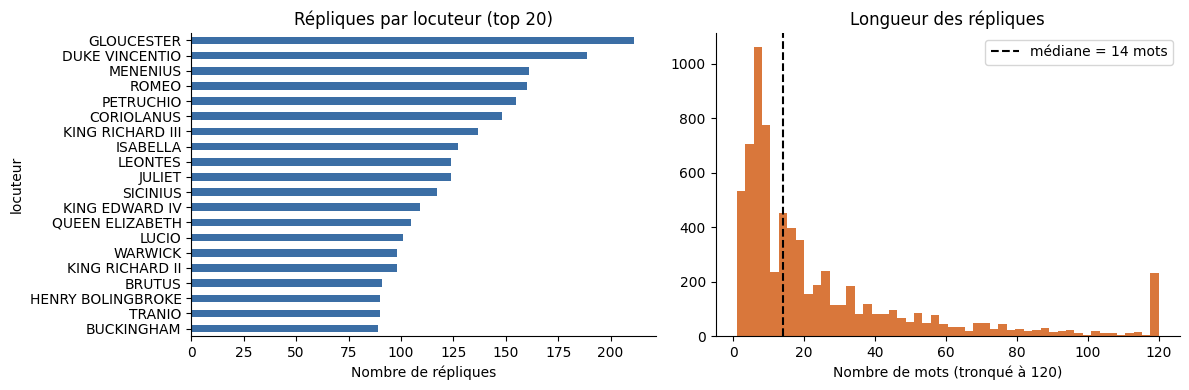

In [5]:
top20 = df["locuteur"].value_counts().head(20)
df["n_mots"] = df["replique"].str.split().str.len()

print("Top 10 locuteurs :")
print(top20.head(10).to_string())
print("\nLongueur des répliques (en mots) :")
print(df["n_mots"].describe().round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

top20.plot(kind="barh", ax=axes[0], color="#3b6ea5")
axes[0].invert_yaxis()
axes[0].set_title("Répliques par locuteur (top 20)")
axes[0].set_xlabel("Nombre de répliques")

axes[1].hist(df["n_mots"].clip(upper=120), bins=50, color="#d9773b")
axes[1].axvline(df["n_mots"].median(), color="black", ls="--",
                label=f"médiane = {df['n_mots'].median():.0f} mots")
axes[1].set_title("Longueur des répliques")
axes[1].set_xlabel("Nombre de mots (tronqué à 120)")
axes[1].legend()

plt.tight_layout()
plt.show()

La distribution est très déséquilibrée : le premier personnage dépasse les 200 répliques, alors que la plupart des 297 locuteurs n'apparaissent que quelques fois. Garder tout le monde rendrait l'apprentissage impossible sur les petites classes.

La médiane est de 14 mots (pour une moyenne à 27,2 tirée par les longues tirades). C'est court pour classer du texte : en TF-IDF, chaque réplique n'activera qu'une petite fraction du vocabulaire, donc la matrice sera très creuse.

## 4. Cadrage de la tâche

Pour garder un problème lisible et suffisamment peuplé par classe :

- Je retiens les 5 locuteurs les plus fréquents (de 126 à 196 répliques après filtrage), ce qui laisse une matrice de confusion 5x5 facile à lire.
- Je filtre les répliques de moins de 5 mots (`MIN_MOTS = 5`) : des phrases comme « Ay, my lord » ou « Speak, speak » n'aident guère à reconnaître qui parle.

In [6]:
N_LOCUTEURS = 5
MIN_MOTS = 5

top_locuteurs = df["locuteur"].value_counts().head(N_LOCUTEURS).index
donnees = (
    df[df["locuteur"].isin(top_locuteurs) & (df["n_mots"] >= MIN_MOTS)]
    .loc[:, ["replique", "locuteur"]]
    .reset_index(drop=True)
)

comptes = donnees["locuteur"].value_counts()
print(comptes.to_string())
print(f"\nTotal : {len(donnees)} répliques")
print(f"Ratio max/min : {comptes.max() / comptes.min():.2f}")
print(f"Part de la classe majoritaire : {comptes.max() / len(donnees):.1%}")

locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126

Total : 761 répliques
Ratio max/min : 1.56
Part de la classe majoritaire : 25.8%


La classe majoritaire (Gloucester) représente 25,8 % des exemples. Une baseline qui prédit toujours ce personnage tournera donc autour de 26 % d'accuracy.

## 5. Découpage train / test

On découpe avant toute vectorisation pour éviter que les fréquences IDF ou le vocabulaire ne fuient du test vers le train. Comme les classes vont de 126 à 196 exemples, on stratifie le split.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    donnees["replique"],
    donnees["locuteur"],
    test_size=0.20,
    stratify=donnees["locuteur"],
    random_state=RANDOM_STATE,
)

print(f"train : {len(X_train)} | test : {len(X_test)}\n")
print(pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3))

train : 608 | test : 153

                train   test
locuteur                    
GLOUCESTER      0.257  0.261
DUKE VINCENTIO  0.217  0.216
ROMEO           0.186  0.183
PETRUCHIO       0.174  0.176
MENENIUS        0.166  0.163


## 6. Vectorisation TF-IDF

Quelques choix sur les paramètres :

- `ngram_range=(1, 2)` pour capter des bigrammes fréquents (`my lord`, `good sir`) en plus des mots isolés.
- `min_df=2` et `max_df=0.8` pour écarter les hapax qui sur-apprennent et les termes trop génériques.
- `sublinear_tf=True` pour tasser l'effet des mots répétés dans une même tirade.
- `stop_words=None` : je laisse les mots outils anglais (`thou`, `thy`, `my`, `sir`), parce qu'ils participent au registre d'un personnage. De toute façon, la pondération IDF baisse déjà le poids des mots très communs.

In [8]:
def creer_tfidf(stop_words=None):
    return TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.8,
        stop_words=stop_words,
        sublinear_tf=True,
    )


vectoriseur = creer_tfidf()
Xtr = vectoriseur.fit_transform(X_train)
Xte = vectoriseur.transform(X_test)

densite = Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1])
dense_mo = Xtr.shape[0] * Xtr.shape[1] * 8 / 1e6
creux_mo = (Xtr.data.nbytes + Xtr.indices.nbytes + Xtr.indptr.nbytes) / 1e6

print(f"Vocabulaire : {len(vectoriseur.vocabulary_):,} termes")
print(f"Matrice train : {Xtr.shape} | test : {Xte.shape}")
print(f"Taux de valeurs non nulles : {densite:.2%} ({1 - densite:.2%} de zéros)")
print(f"Mémoire : {creux_mo:.2f} Mo en creux contre {dense_mo:.1f} Mo en dense")

Vocabulaire : 3,464 termes
Matrice train : (608, 3464) | test : (153, 3464)
Taux de valeurs non nulles : 0.97% (99.03% de zéros)
Mémoire : 0.25 Mo en creux contre 16.8 Mo en dense


La matrice contient 99 % de zéros : chaque réplique courte n'active qu'une poignée de colonnes sur les 3 464 du vocabulaire. Sur de gros corpus, le stockage dense exploserait, d'où les matrices creuses (`scipy.sparse`). C'est aussi ce qui rend les modèles linéaires bien plus à l'aise ici que les arbres de décision.

Vérifions les scores IDF extrêmes pour voir ce que la pondération met en avant ou atténue.

In [9]:
idf = pd.Series(vectoriseur.idf_, index=vectoriseur.get_feature_names_out())
print("IDF les plus forts (rares) :")
print(idf.sort_values(ascending=False).head(10).round(2).to_string())
print("\nIDF les plus faibles (très fréquents) :")
print(idf.sort_values().head(10).round(2).to_string())

IDF les plus forts (rares) :
your sister          6.31
able                 6.31
your general         6.31
your ear             6.31
your company         6.31
your cause           6.31
your best            6.31
youngest daughter    6.31
young edward         6.31
afternoon            6.31

IDF les plus faibles (très fréquents) :
and     1.72
the     1.74
to      1.82
you     1.98
of      2.09
that    2.18
is      2.25
in      2.29
not     2.32
my      2.36


Les termes à IDF faible (`and`, `the`, `to`, `you`, `of`) correspondent à peu près à une liste de stopwords standard, sauf que TF-IDF les atténue automatiquement selon le corpus sans risquer de supprimer un mot utile propre à un locuteur.

## 7. Modélisation

### 7.1 Baselines

Avant d'essayer de vrais modèles, on mesure le plancher avec deux `DummyClassifier` : prédiction constante de la classe majoritaire et tirage aléatoire stratifié.

In [10]:
baselines = {
    "Dummy (majoritaire)": DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE),
    "Dummy (stratifié)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
}

for nom, modele in baselines.items():
    modele.fit(Xtr, y_train)
    pred = modele.predict(Xte)
    print(f"{nom:<22} acc = {accuracy_score(y_test, pred):.3f}   "
          f"F1 macro = {f1_score(y_test, pred, average='macro'):.3f}")

Dummy (majoritaire)    acc = 0.261   F1 macro = 0.083
Dummy (stratifié)      acc = 0.196   F1 macro = 0.189


En prédisant uniquement Gloucester, la baseline atteint 0,261 d'accuracy mais s'écroule à 0,083 en F1 macro (rappel nul sur les 4 autres personnages). D'où l'intérêt de suivre le F1 macro plutôt que la seule accuracy.

### 7.2 Modèles supervisés

On teste trois classiques adaptés aux vecteurs TF-IDF creux :

- Naive Bayes multinomial (`alpha=0.5`), rapide et souvent solide sur peu de données.
- Régression logistique (`C=5`), linéaire et régularisée, avec des poids faciles à relire.
- SVM linéaire (`C=1`).

Pour la régression logistique et le SVM, je garde `class_weight="balanced"` afin de ne pas favoriser Gloucester par rapport à Ménénius ou Petruchio.

In [11]:
modeles = {
    "Naive Bayes": MultinomialNB(alpha=0.5),
    "Régression logistique": LogisticRegression(
        max_iter=2000, C=5, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "SVM linéaire": LinearSVC(C=1, class_weight="balanced", random_state=RANDOM_STATE),
}

resultats = {}
modeles_entraines = {}

for nom, modele in modeles.items():
    modele.fit(Xtr, y_train)
    resultats[nom] = modele.predict(Xte)
    modeles_entraines[nom] = modele

## 8. Évaluation et analyse

### 8.1 Comparaison des métriques

In [12]:
pred_base = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE).fit(Xtr, y_train).predict(Xte)
tous = {"Baseline": pred_base, **resultats}

lignes = []
for nom, pred in tous.items():
    lignes.append({
        "modèle": nom,
        "accuracy": accuracy_score(y_test, pred),
        "précision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "rappel (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_test, pred, average="weighted", zero_division=0),
    })

tableau = pd.DataFrame(lignes).set_index("modèle").round(3)
tableau

,accuracy,précision (macro),rappel (macro),F1 (macro),F1 (weighted)
modèle,,,,,
Baseline,0.261,0.052,0.200,0.083,0.108
Naive Bayes,0.621,0.725,0.597,0.619,0.619
Régression logistique,0.667,0.673,0.668,0.669,0.667
SVM linéaire,0.647,0.652,0.649,0.649,0.647


La métrique principale que je retiens est le **F1 macro**, puisque les classes sont un peu déséquilibrées et qu'on traite les 5 personnages à égalité. La régression logistique arrive en tête avec 0,669 de F1 macro (et 0,667 d'accuracy), juste devant le SVM linéaire (0,649) et Naive Bayes (0,619).

In [13]:
meilleur = tableau.drop("Baseline")["F1 (macro)"].idxmax()
print(f"Détail pour : {meilleur}\n")
print(classification_report(y_test, resultats[meilleur], digits=3))

Détail pour : Régression logistique

                precision    recall  f1-score   support

DUKE VINCENTIO      0.697     0.697     0.697        33
    GLOUCESTER      0.650     0.650     0.650        40
      MENENIUS      0.667     0.720     0.692        25
     PETRUCHIO      0.773     0.630     0.694        27
         ROMEO      0.581     0.643     0.610        28

      accuracy                          0.667       153
     macro avg      0.673     0.668     0.669       153
  weighted avg      0.672     0.667     0.667       153



### 8.2 Matrice de confusion

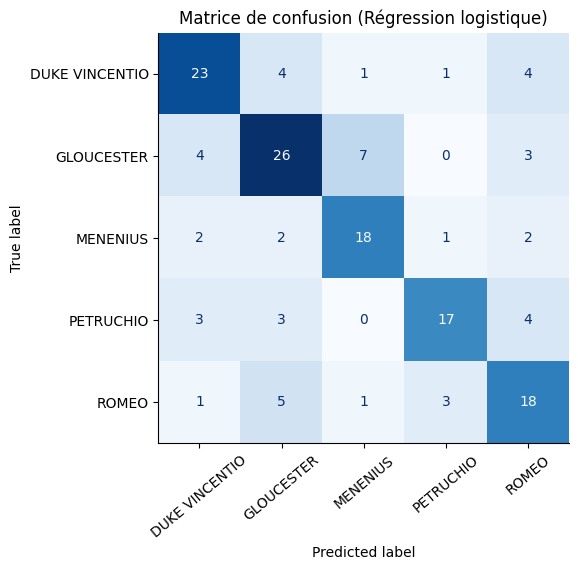

Confusions les plus fréquentes :
          vrai         prédit  erreurs % classe
    GLOUCESTER       MENENIUS        7    17.5%
         ROMEO     GLOUCESTER        5    17.9%
     PETRUCHIO          ROMEO        4    14.8%
DUKE VINCENTIO     GLOUCESTER        4    12.1%
    GLOUCESTER DUKE VINCENTIO        4    10.0%
DUKE VINCENTIO          ROMEO        4    12.1%
         ROMEO      PETRUCHIO        3    10.7%
     PETRUCHIO     GLOUCESTER        3    11.1%


In [14]:
fig, ax = plt.subplots(figsize=(6.8, 5.8))
ConfusionMatrixDisplay.from_predictions(
    y_test, resultats[meilleur],
    xticks_rotation=40, cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title(f"Matrice de confusion ({meilleur})")
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, resultats[meilleur])
classes = sorted(y_test.unique())
paires = [
    {
        "vrai": classes[i],
        "prédit": classes[j],
        "erreurs": int(cm[i, j]),
        "% classe": cm[i, j] / cm[i].sum(),
    }
    for i in range(len(classes))
    for j in range(len(classes))
    if i != j and cm[i, j] > 0
]
print("Confusions les plus fréquentes :")
print(pd.DataFrame(paires).sort_values("erreurs", ascending=False)
      .head(8).to_string(index=False, formatters={"% classe": "{:.1%}".format}))

### 8.3 Ce que le modèle regarde vraiment

En observant les poids de la régression logistique, on peut vérifier si le modèle capte un style d'écriture ou autre chose.

In [15]:
modele_lr = modeles_entraines["Régression logistique"]
termes = np.array(vectoriseur.get_feature_names_out())

for i, classe in enumerate(modele_lr.classes_):
    top = np.argsort(modele_lr.coef_[i])[-12:][::-1]
    print(f"{classe:<16} : {', '.join(termes[top])}")

DUKE VINCENTIO   : you, angelo, duke, him, provost, claudio, the duke, your, he, ere, die, lord angelo
GLOUCESTER       : clarence, king, edward, lord, god, my lord, warwick, cousin, kill, myself, madam, brother
MENENIUS         : marcius, he, rome, like, you, tribunes, general, you have, pray, mother, could, the
PETRUCHIO        : kate, hortensio, come, sir, and, her, not, why, sirrah, me, knock, end
ROMEO            : love, mercutio, goose, what shall, thy, night, thou, dream, light, wilt, lips, romeo


En regardant les mots les plus discriminants, on tombe tout de suite sur des noms propres et des termes d'intrigue propres à chaque pièce : `angelo`, `provost`, `claudio` pour Duke Vincentio (*Mesure pour mesure*), `clarence`, `edward`, `warwick` pour Gloucester (*Richard III*), `marcius`, `rome`, `tribunes` pour Ménénius (*Coriolan*), `kate`, `hortensio` pour Petruchio (*La Mégère apprivoisée*), `mercutio`, `romeo` pour Roméo.

Autrement dit, le modèle reconnaît surtout **la pièce** d'où vient la réplique plutôt que la façon de parler du personnage. Comme chaque personnage du top 5 appartient à une pièce différente, identifier la pièce suffit à deviner le locuteur sur ce dataset, mais le modèle ne généraliserait pas à un autre personnage de la même pièce.

Pour mesurer ce biais, on peut retirer les mots capitalisés du corpus et réentraîner le même modèle.

In [16]:
noms_propres = {mot.lower() for mot in re.findall(r"\b[A-Z][a-z]{2,}\b", texte)}
print(f"{len(noms_propres):,} candidats retirés")

vec_sans_noms = creer_tfidf(stop_words=sorted(noms_propres))
Xtr2 = vec_sans_noms.fit_transform(X_train)
Xte2 = vec_sans_noms.transform(X_test)

m2 = LogisticRegression(max_iter=2000, C=5, class_weight="balanced", random_state=RANDOM_STATE)
m2.fit(Xtr2, y_train)
p2 = m2.predict(Xte2)

f1_avec = f1_score(y_test, resultats["Régression logistique"], average="macro")
f1_sans = f1_score(y_test, p2, average="macro")
print(f"F1 macro avec : {f1_avec:.3f}")
print(f"F1 macro sans : {f1_sans:.3f} ({f1_sans - f1_avec:+.3f}, soit {(f1_sans / f1_avec - 1):+.1%})")

2,557 candidats retirés
F1 macro avec : 0.669
F1 macro sans : 0.421 (-0.247, soit -37.0%)


Le score chute nettement (de 0,669 à 0,421). L'heuristique est un peu large parce qu'elle attrape aussi des mots ordinaires placés en début de vers ou de phrase, donc la baisse exacte est sans doute surestimée ici, mais la dépendance aux noms propres reste claire.

Regardons enfin quelques erreurs sur le test.

In [17]:
erreurs = pd.DataFrame({
    "replique": X_test.values,
    "vrai": y_test.values,
    "prédit": resultats[meilleur],
})
erreurs = erreurs[erreurs["vrai"] != erreurs["prédit"]]
print(f"{len(erreurs)} erreurs sur {len(y_test)} exemples de test\n")

for _, r in erreurs.head(5).iterrows():
    extrait = r["replique"][:200] + ("..." if len(r["replique"]) > 200 else "")
    print(f"[{r['vrai']} -> prédit {r['prédit']}] « {extrait} »\n")

51 erreurs sur 153 exemples de test

[ROMEO -> prédit GLOUCESTER] « Switch and spurs, switch and spurs; or I'll cry a match. »

[PETRUCHIO -> prédit ROMEO] « Why, thou say'st true; it is a paltry cap, A custard-coffin, a bauble, a silken pie: I love thee well, in that thou likest it not. »

[PETRUCHIO -> prédit GLOUCESTER] « Twenty crowns! I'll venture so much of my hawk or hound, But twenty times so much upon my wife. »

[GLOUCESTER -> prédit ROMEO] « By so much is the wonder in extremes. »

[ROMEO -> prédit GLOUCESTER] « O, I am fortune's fool! »



Sur des répliques courtes et isolées comme « By so much is the wonder in extremes », même un lecteur humain aurait du mal à trancher sans le contexte de la scène. Il y a donc un plafond naturel à la tâche.

Côté protocole, le split a bien été fait avant TF-IDF et avec stratification. Par contre, `C=5` ou `alpha=0.5` ont été fixés directement ici : sans jeu de validation séparé ni validation croisée préalable, le score de test reste un peu optimiste.

## 9. Quelques tests complémentaires

### 9.1 Validation croisée avec Pipeline

Enchaîner TF-IDF et classifieur dans un `Pipeline` scikit-learn garantit que le vectoriseur n'est ajusté que sur les 4 folds d'entraînement à chaque itération.

In [18]:
pipe = Pipeline([
    ("tfidf", creer_tfidf()),
    ("clf", LogisticRegression(max_iter=2000, C=5, class_weight="balanced", random_state=RANDOM_STATE)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")

print("F1 macro par fold :", np.round(scores, 3))
print(f"Moyenne : {scores.mean():.3f} (+/- {scores.std():.3f})")

F1 macro par fold : [0.584 0.554 0.609 0.595 0.627]
Moyenne : 0.594 (+/- 0.024)


Avec seulement 608 répliques en train, l'écart-type entre folds atteint 0,024 (entre 0,554 et 0,627). À cette échelle, deux modèles séparés de moins de 0,02 point sont difficiles à départager.

### 9.2 Comptages bruts (BoW) contre TF-IDF

In [19]:
comparaison_vec = {}
for nom, vec in [
    ("CountVectorizer (BoW)", CountVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.8)),
    ("TfidfVectorizer", creer_tfidf()),
]:
    A = vec.fit_transform(X_train)
    B = vec.transform(X_test)
    m = LogisticRegression(max_iter=2000, C=5, class_weight="balanced", random_state=RANDOM_STATE).fit(A, y_train)
    p = m.predict(B)
    comparaison_vec[nom] = {
        "accuracy": accuracy_score(y_test, p),
        "F1 macro": f1_score(y_test, p, average="macro"),
    }

pd.DataFrame(comparaison_vec).T.round(3)

,accuracy,F1 macro
CountVectorizer (BoW),0.569,0.570
TfidfVectorizer,0.667,0.669


Passer des comptages bruts à TF-IDF avec normalisation sous-linéaire fait gagner près de 10 points de F1 macro (0,570 à 0,669).

### 9.3 Effet du nombre de classes

In [20]:
def evaluer_n_classes(n_locuteurs, min_mots=5):
    top = df["locuteur"].value_counts().head(n_locuteurs).index
    d = df[df["locuteur"].isin(top) & (df["n_mots"] >= min_mots)]
    Xa, Xb, ya, yb = train_test_split(
        d["replique"], d["locuteur"], test_size=0.2,
        stratify=d["locuteur"], random_state=RANDOM_STATE,
    )
    v = creer_tfidf()
    A, B = v.fit_transform(Xa), v.transform(Xb)
    m = LogisticRegression(max_iter=2000, C=5, class_weight="balanced", random_state=RANDOM_STATE).fit(A, ya)
    p = m.predict(B)
    return {
        "exemples": len(d),
        "baseline acc.": yb.value_counts(normalize=True).max(),
        "accuracy": accuracy_score(yb, p),
        "F1 macro": f1_score(yb, p, average="macro"),
    }


pd.DataFrame(
    [evaluer_n_classes(n) for n in (2, 3, 5, 10, 20)],
    index=pd.Index([2, 3, 5, 10, 20], name="n classes"),
).round(3)

,exemples,baseline acc.,accuracy,F1 macro
n classes,,,,
2,361,0.548,0.781,0.777
3,487,0.408,0.704,0.704
5,761,0.261,0.667,0.669
10,1310,0.149,0.447,0.425
20,2181,0.089,0.318,0.308


Quand le nombre de locuteurs augmente de 2 à 20, l'accuracy passe de 0,781 à 0,318, mais la baseline descend elle aussi de 0,548 à 0,089. Il faut donc toujours lire le score par rapport au hasard ou à la classe majoritaire.

En résumé, sur ce corpus, une régression logistique sur TF-IDF atteint 0,669 de F1 macro contre 0,083 pour la baseline, mais l'inspection des poids montre qu'elle s'appuie largement sur les noms propres et le vocabulaire thématique de chaque pièce.